In [14]:
import datetime
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd

Import Acled events data

In [6]:
PATH_TO_ACLED_EVENTS = '../data/raw/Middle-East_aggregated_data_up_to_week_of-2026-10-31.csv'

df_events = pd.read_csv(PATH_TO_ACLED_EVENTS)

In [60]:
#df_events.head()

### Preprocessing

In [9]:
df_events.dtypes

WEEK                    object
REGION                  object
COUNTRY                 object
ADMIN1                  object
EVENT_TYPE              object
SUB_EVENT_TYPE          object
EVENTS                   int64
FATALITIES               int64
POPULATION_EXPOSURE    float64
DISORDER_TYPE           object
ID                       int64
CENTROID_LATITUDE      float64
CENTROID_LONGITUDE     float64
dtype: object

In [58]:
# strip whitespaces
string_cols = ['REGION', 'COUNTRY', 'ADMIN1', 'EVENT_TYPE', 'SUB_EVENT_TYPE', 'DISORDER_TYPE']
df_events[string_cols] = df_events[string_cols].apply(lambda x: x.str.strip())
#df_events[string_cols].head()

In [16]:
# format date columns
df_events['WEEK'] = pd.to_datetime(df_events['WEEK'])
df_events['WEEK'].head()

0   2016-02-06
1   2026-02-28
2   2026-03-07
3   2026-03-14
4   2026-03-21
Name: WEEK, dtype: datetime64[ns]

In [31]:
# create date grouping columns
df_events['YEAR'] = df_events['WEEK'].dt.year
df_events['YEARMO'] = df_events['WEEK'].dt.to_period('M').astype(str)
df_events['YEAR_WEEK'] = df_events['WEEK'].dt.to_period('W').astype(str)

<br> 

Filter for Palestine events

In [19]:
mask_palestine_events = df_events.COUNTRY == 'Palestine'
df_events = df_events[mask_palestine_events]

## EDA

#### **NOTE: Counts

At least for sprint 1, I am choosing to count the number of rows as the number of events for simplicity. This is therefore an underestimate, since the "EVENTS" column in df_events indicates there can be multiple occurrences of a given event at the same location in that week.

#### What geography is covered?

In [38]:
pd.concat([
    df_events['ADMIN1'].value_counts().rename('count'),
    df_events['ADMIN1'].value_counts(normalize=True).round(2).rename('ratio')
], axis=1)

,count,ratio
ADMIN1,,
West Bank,4690,0.6
Gaza Strip,3159,0.4


### Different Event types

In [26]:
pd.concat([
    df_events['EVENT_TYPE'].value_counts().rename('count'),
    df_events['EVENT_TYPE'].value_counts(normalize=True).round(2).rename('ratio')
], axis=1)

,count,ratio
EVENT_TYPE,,
Strategic developments,2528,0.32
Protests,1331,0.17
Riots,1210,0.15
Explosions/Remote violence,1165,0.15
Violence against civilians,917,0.12
Battles,698,0.09


### Different sub event types

In [27]:
pd.concat([
    df_events['SUB_EVENT_TYPE'].value_counts().rename('count'),
    df_events['SUB_EVENT_TYPE'].value_counts(normalize=True).round(2).rename('ratio')
], axis=1)

,count,ratio
SUB_EVENT_TYPE,,
Other,905,0.12
Looting/property destruction,870,0.11
Attack,859,0.11
Peaceful protest,828,0.11
Armed clash,697,0.09
Mob violence,642,0.08
Violent demonstration,568,0.07
Shelling/artillery/missile attack,359,0.05
Air/drone strike,343,0.04


### Different disorder types

In [28]:
pd.concat([
    df_events['DISORDER_TYPE'].value_counts().rename('count'),
    df_events['DISORDER_TYPE'].value_counts(normalize=True).round(2).rename('ratio')
], axis=1)

,count,ratio
DISORDER_TYPE,,
Political violence,3422,0.44
Strategic developments,2528,0.32
Demonstrations,1721,0.22
Political violence; Demonstrations,178,0.02


### Date range

In [35]:
print(f"Start date: {df_events['WEEK'].min():%Y-%m}")
print(f"End date:   {df_events['WEEK'].max():%Y-%m}")

Start date: 2015-12
End date:   2026-10


### Events over time

#### Gaza vs West Bank

ADMIN1,Gaza Strip,West Bank
YEAR,,
2015,0,2
2016,177,309
2017,214,349
2018,411,372
2019,344,394
2020,223,424
2021,210,441
2022,178,437
2023,242,523


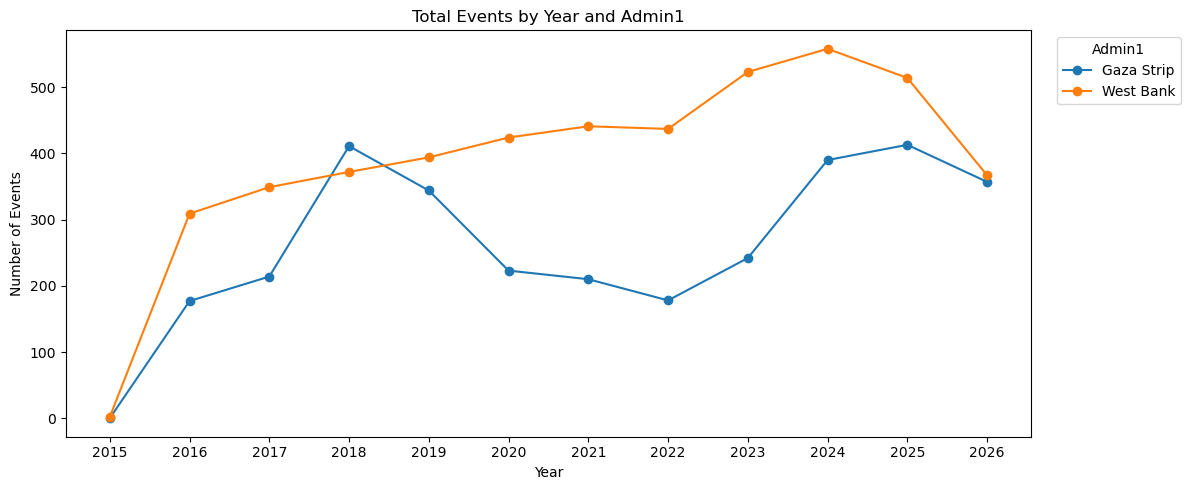

In [41]:
events_year = (
    df_events.groupby(['YEAR', 'ADMIN1'])
    .size()
    .unstack(fill_value=0)
)

ax = events_year.plot(
    kind='line',
    figsize=(12, 5),
    marker='o'
)

ax.set_title('Total Events by Year and Admin1')
ax.set_xlabel('Year')
ax.set_ylabel('Number of Events')
ax.legend(title='Admin1', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.set_xticks(events_year.index)

display(events_year)
plt.tight_layout()
plt.show()

#### TODO: Seasonality? 

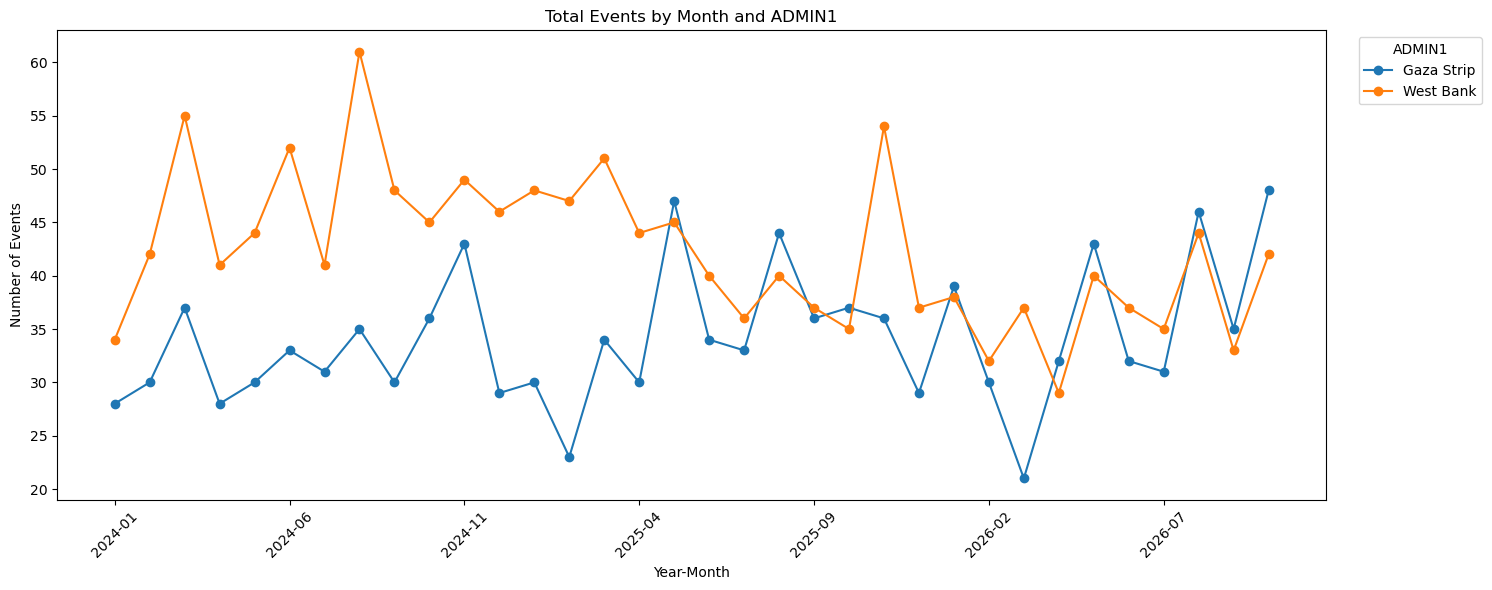

In [44]:
mask_min_date = df_events.YEAR > 2023

events_month = (
    df_events[mask_min_date].groupby(['YEARMO', 'ADMIN1'])
    .size()
    .unstack(fill_value=0)
)

ax = events_month.plot(
    kind='line',
    figsize=(15, 6),
    marker='o'
)

ax.set_title('Total Events by Month and ADMIN1')
ax.set_xlabel('Year-Month')
ax.set_ylabel('Number of Events')
ax.legend(title='ADMIN1', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

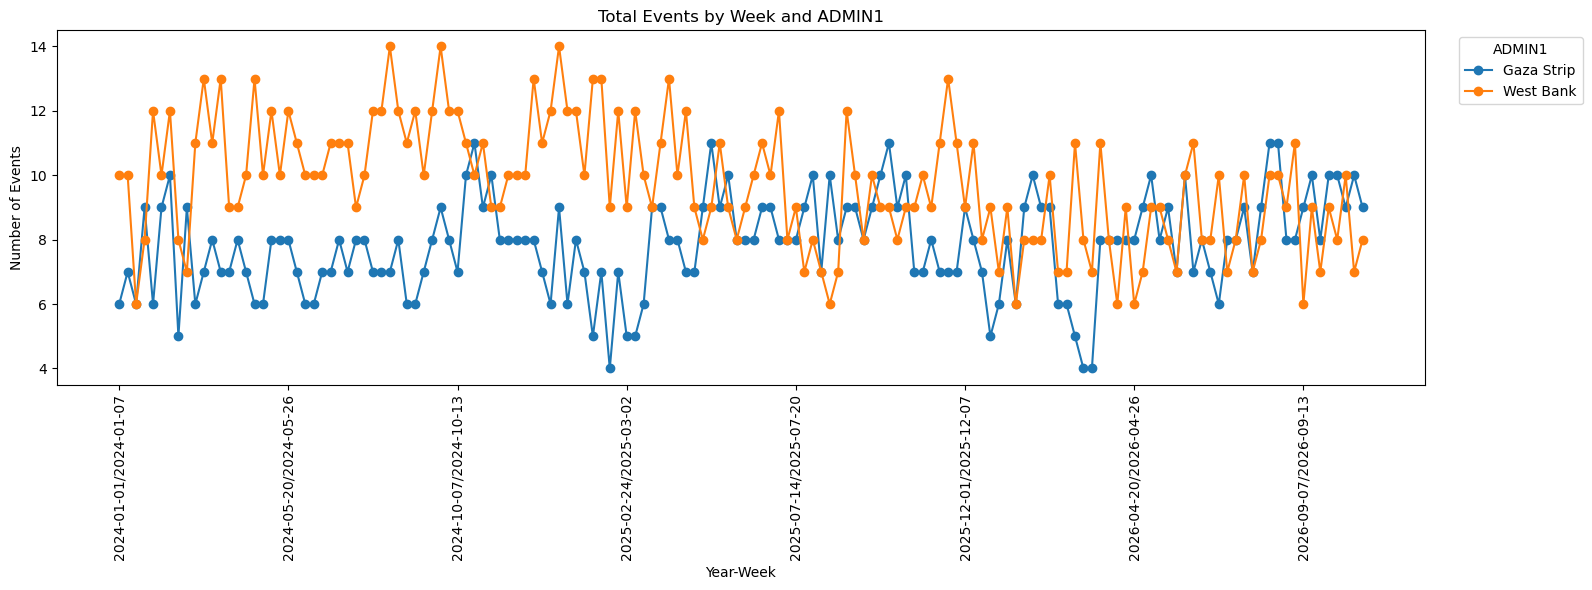

In [46]:
events_week = (
    df_events[mask_min_date].groupby(['YEAR_WEEK', 'ADMIN1'])
    .size()
    .unstack(fill_value=0)
)

ax = events_week.plot(
    kind='line',
    figsize=(16, 6),
    marker='o'
)

ax.set_title('Total Events by Week and ADMIN1')
ax.set_xlabel('Year-Week')
ax.set_ylabel('Number of Events')
ax.legend(title='ADMIN1', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

#### by Event Type

EVENT_TYPE,Battles,Explosions/Remote violence,Protests,Riots,Strategic developments,Violence against civilians
YEAR,,,,,,
2016,6,32,24,31,61,23
2017,9,33,41,31,87,13
2018,32,87,92,65,106,29
2019,29,64,57,52,110,32
2020,21,48,48,5,82,19
2021,7,35,52,7,93,16
2022,8,20,49,4,87,10
2023,22,55,41,16,82,26
2024,52,147,6,2,130,53


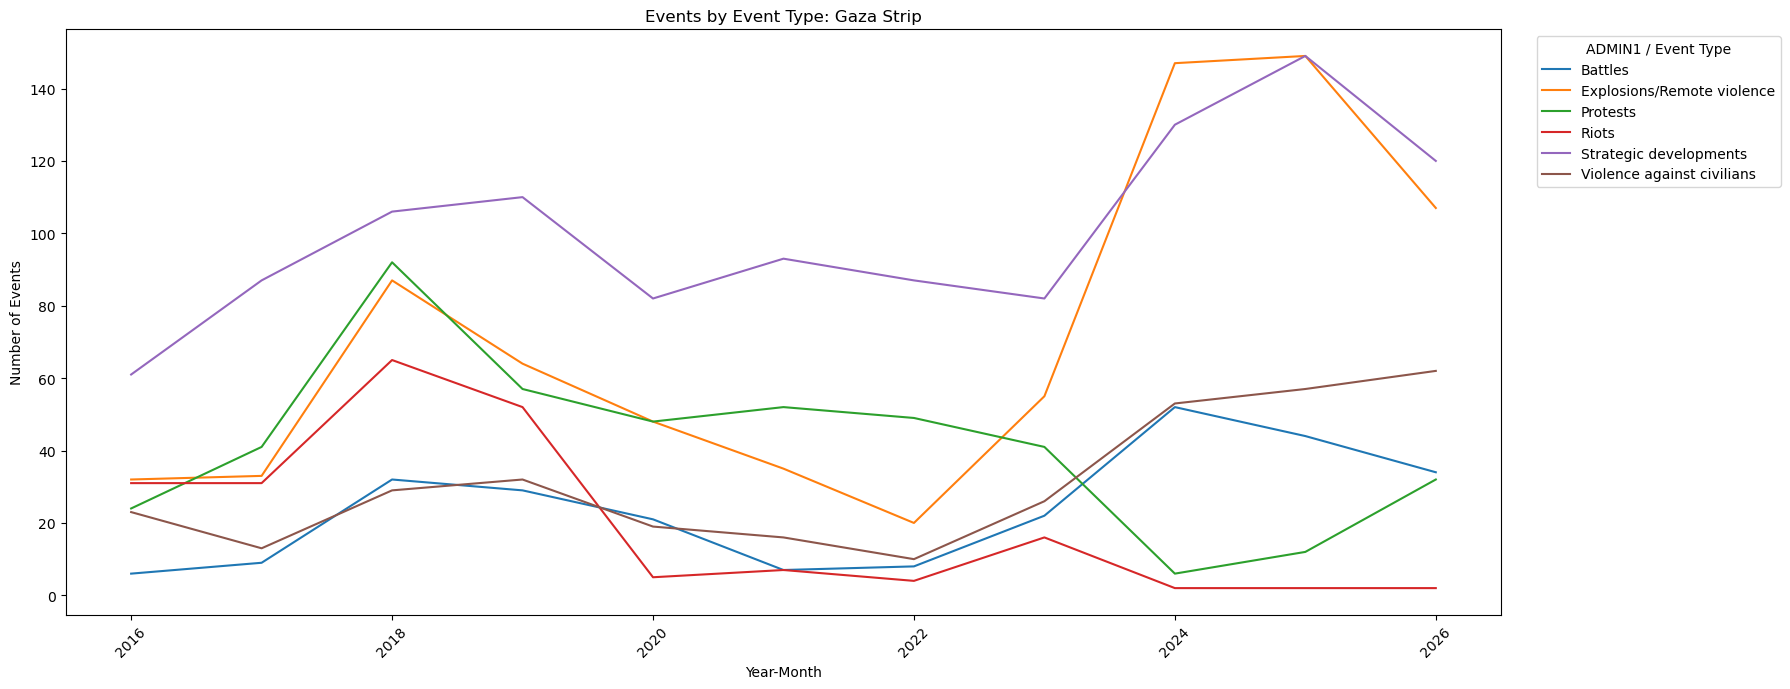

EVENT_TYPE,Battles,Explosions/Remote violence,Protests,Riots,Strategic developments,Violence against civilians
YEAR,,,,,,
2015,0,0,0,1,1,0
2016,43,5,64,70,79,48
2017,33,6,83,94,86,47
2018,28,6,84,103,100,51
2019,29,7,71,102,134,51
2020,33,12,92,101,133,53
2021,43,17,109,102,117,53
2022,53,32,94,106,99,53
2023,52,84,92,103,138,54


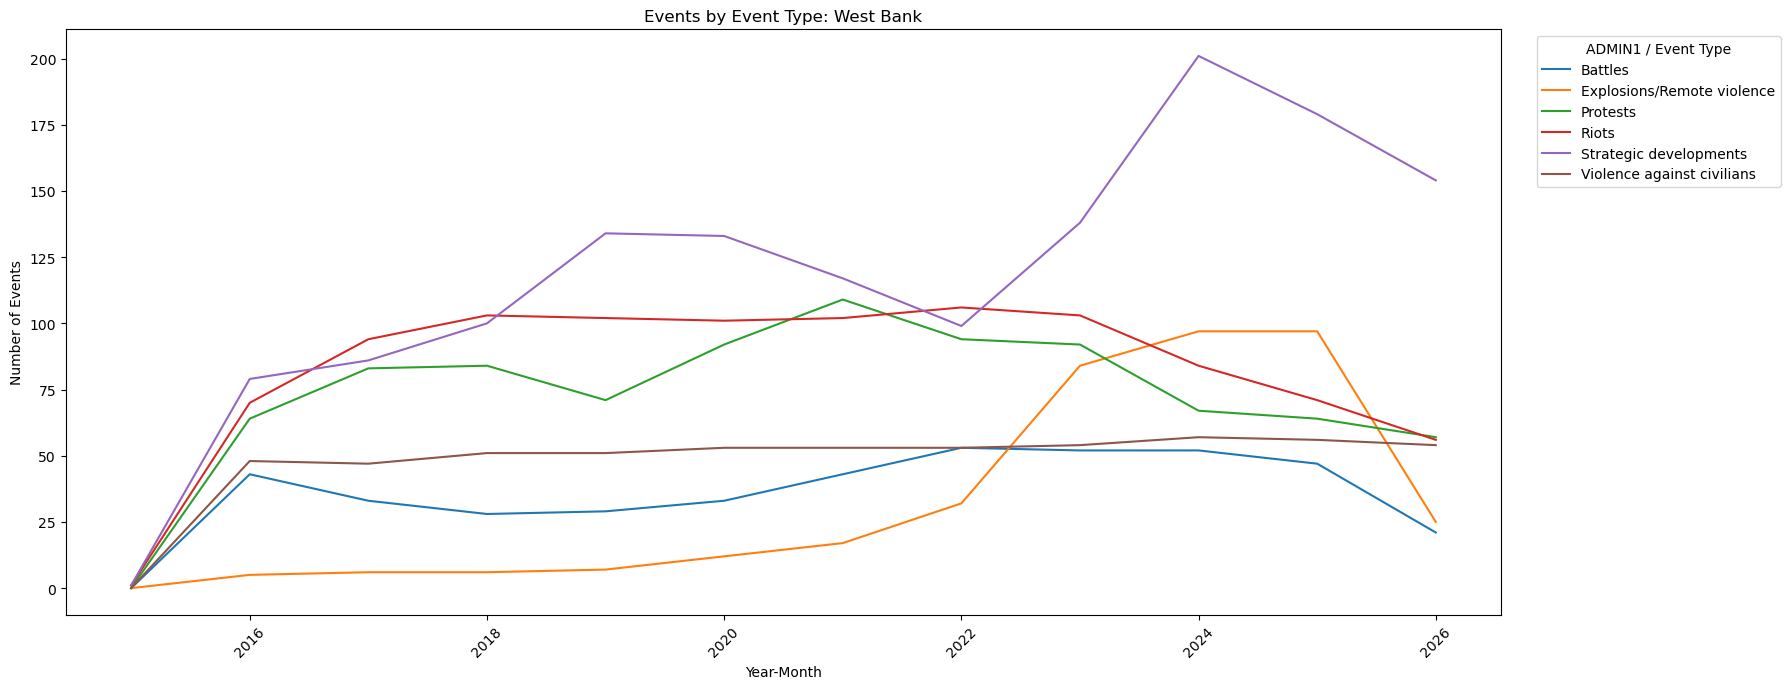

In [53]:
for admin in df_events.ADMIN1.unique():
    mask_admin = df_events.ADMIN1==admin
    events_by_type = (
        df_events[mask_admin].groupby(['YEAR', 'EVENT_TYPE'])
        .size()
        .unstack(fill_value=0)
    )
    
    ax = events_by_type.plot(
        kind='line',
        figsize=(18, 7)
    )
    
    ax.set_title(f'Events by Event Type: {admin}')
    ax.set_xlabel('Year-Month')
    ax.set_ylabel('Number of Events')
    ax.legend(title='ADMIN1 / Event Type', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.xticks(rotation=45)
    display(events_by_type)
    plt.tight_layout()
    plt.show()

#### by Sub Event Type

#### TODO: distill from noise

SUB_EVENT_TYPE,Abduction/forced disappearance,Agreement,Air/drone strike,Armed clash,Arrests,Attack,Change to group/activity,Disrupted weapons use,Excessive force against protesters,Grenade,...,Mob violence,Non-state actor overtakes territory,Other,Peaceful protest,Protest with intervention,Remote explosive/landmine/IED,Sexual violence,Shelling/artillery/missile attack,Suicide bomb,Violent demonstration
YEAR,,,,,,,,,,,,,,,,,,,,,
2016,0,0,12,6,1,23,3,1,4,0,...,26,0,47,18,2,6,0,14,0,5
2017,0,0,14,9,0,13,23,7,5,0,...,19,0,38,35,1,6,0,12,1,12
2018,0,5,36,32,1,29,8,7,51,9,...,15,0,52,32,9,11,0,31,0,50
2019,0,7,28,29,0,32,17,5,21,2,...,4,0,52,30,6,1,0,32,1,48
2020,1,2,21,21,0,18,6,3,3,0,...,2,0,52,44,1,1,0,26,0,3
2021,0,1,17,7,0,16,7,1,3,0,...,1,0,52,47,2,4,0,14,0,6
2022,0,0,8,8,0,10,1,2,1,0,...,3,0,53,48,0,0,0,12,0,1
2023,2,0,20,22,3,24,3,3,2,3,...,1,0,48,37,2,9,0,23,0,15
2024,6,0,52,52,7,46,24,9,0,0,...,2,0,37,6,0,43,1,52,0,0


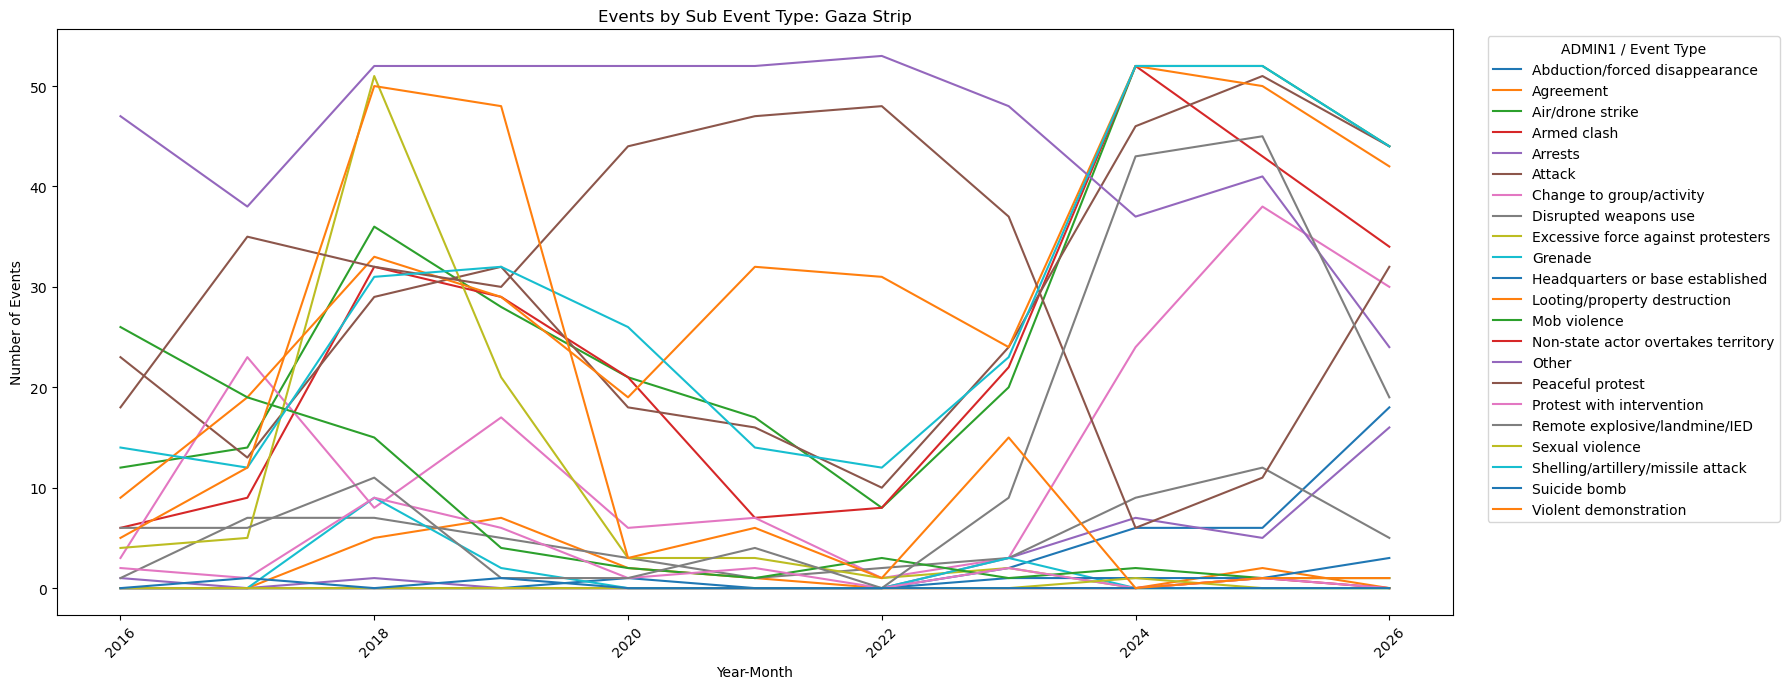

SUB_EVENT_TYPE,Abduction/forced disappearance,Air/drone strike,Armed clash,Arrests,Attack,Change to group/activity,Disrupted weapons use,Excessive force against protesters,Grenade,Headquarters or base established,Looting/property destruction,Mob violence,Non-violent transfer of territory,Other,Peaceful protest,Protest with intervention,Remote explosive/landmine/IED,Sexual violence,Shelling/artillery/missile attack,Violent demonstration
YEAR,,,,,,,,,,,,,,,,,,,,
2015,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0
2016,0,0,43,4,48,12,7,11,1,0,46,53,0,10,26,27,2,0,2,17
2017,0,0,33,4,47,31,4,11,2,0,30,52,4,13,39,33,4,0,0,42
2018,0,0,28,6,51,9,10,16,4,0,48,52,0,27,34,34,2,0,0,51
2019,0,0,29,18,51,26,9,9,3,0,51,52,0,30,40,22,3,0,1,50
2020,2,0,33,14,51,13,5,8,8,1,51,52,0,49,47,37,3,0,1,49
2021,1,0,43,8,52,13,0,10,8,0,51,52,0,45,52,47,7,0,2,50
2022,0,0,53,2,53,3,2,5,26,0,53,53,0,39,53,36,6,0,0,53
2023,1,9,52,9,52,19,10,8,43,0,52,52,0,48,52,32,19,1,13,51


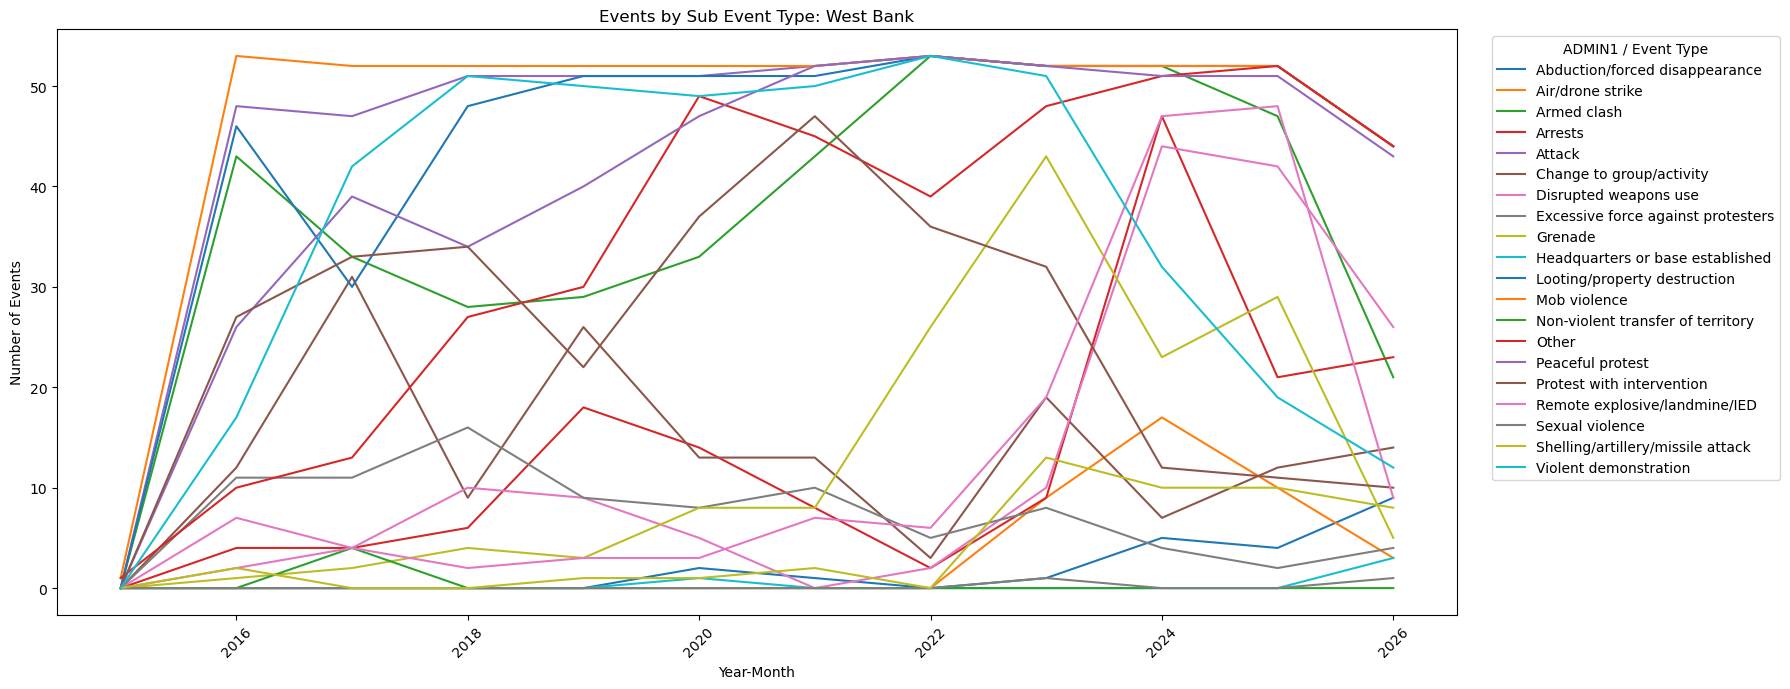

In [54]:
for admin in df_events.ADMIN1.unique():
    mask_admin = df_events.ADMIN1==admin
    events_by_type = (
        df_events[mask_admin].groupby(['YEAR', 'SUB_EVENT_TYPE'])
        .size()
        .unstack(fill_value=0)
    )
    
    ax = events_by_type.plot(
        kind='line',
        figsize=(18, 7)
    )
    
    ax.set_title(f'Events by Sub Event Type: {admin}')
    ax.set_xlabel('Year-Month')
    ax.set_ylabel('Number of Events')
    ax.legend(title='ADMIN1 / Event Type', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.xticks(rotation=45)
    display(events_by_type)
    plt.tight_layout()
    plt.show()

#### TODO: Handle EVENTS column counts

In [62]:
#df_events.sort_values(by='EVENTS')